# Рекуррентные сети на именах: RNN, GRU и LSTM с нуля

Датасет: 6782 английских имени с полом. Каждое имя это последовательность букв. На нём решаем две задачи:

- **генерация имён**: модель учится предсказывать следующую букву, потом по одной букве придумывает новые имена;
- **классификация пола** по имени.

Ячейки RNN, GRU и LSTM написаны вручную (`rnn.py`), без `nn.RNN` / `nn.GRU` / `nn.LSTM`. Готовые слои из torch используются только в бонусе для сравнения.

## 1. Немного теории

### Где нужны рекуррентные сети

Там, где объект это последовательность и важен порядок: тексты, речь, временные ряды, показания датчиков, действия пользователя. Обычная полносвязная сеть принимает вектор фиксированной длины, а RNN читает последовательность по одному элементу и хранит то, что прочитала, в скрытом состоянии $h_t$.

По форме входа и выхода задачи бывают такие:

| Тип | Что на входе и выходе | Примеры |
|---|---|---|
| many-to-one | последовательность -> одно значение | пол по имени, тональность отзыва |
| one-to-many | одно значение -> последовательность | подпись к картинке, генерация мелодии по жанру |
| many-to-many | последовательность -> последовательность | машинный перевод, разметка частей речи |

### Как RNN читает слово

Пример: сеть, которая определяет язык слова "Hello". Каждая буква превращается в эмбеддинг, ячейка RNN получает эмбеддинг буквы и предыдущее состояние, начальное состояние $h_0$ это нули. Язык предсказываем по последнему состоянию $h_5$ через полносвязные слои и softmax.

![](images/hello_rnn.png)

### RNN, GRU и LSTM

**Обычная RNN**: новое состояние считается из входа и старого состояния

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$$

Проблема: при обратном проходе градиент от конца последовательности к началу много раз умножается на одну и ту же матрицу $W_h$ (и на производную tanh). Он либо затухает, либо взрывается, поэтому RNN плохо помнит то, что было давно.

**GRU** добавляет два гейта (значения от 0 до 1):

$$z_t = \sigma(W_z[x_t, h_{t-1}]), \quad r_t = \sigma(W_r[x_t, h_{t-1}])$$
$$\tilde h_t = \tanh(W[x_t, r_t \odot h_{t-1}]), \quad h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde h_t$$

Если $z_t \approx 0$, состояние просто копируется дальше без умножения на матрицу, и градиент не затухает. Похоже на residual связи в CNN.

**LSTM** хранит отдельную "память" $c_t$ и три гейта: что забыть ($f_t$), что записать ($i_t$), что отдать наружу ($o_t$):

$$c_t = f_t \odot c_{t-1} + i_t \odot \tanh(W_c[x_t, h_{t-1}]), \quad h_t = o_t \odot \tanh(c_t)$$

Память $c_t$ тоже обновляется сложением, а не умножением на матрицу. GRU проще (меньше параметров, нет отдельной памяти), LSTM гибче.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

from rnn import *

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cpu')

## 2. Данные

In [2]:
names = pd.read_csv('data/babynames-clean.csv', names=['name', 'gender'])
names

,name,gender
0,John,boy
1,William,boy
2,James,boy
3,Charles,boy
4,George,boy
...,...,...
6777,Laylah,girl
6778,Carleigh,girl
6779,Kenley,girl
6780,Sloane,girl


In [3]:
print(names.gender.value_counts())
print('дубликатов имён:', names.name.str.lower().duplicated().sum())

gender
boy     3437
girl    3345
Name: count, dtype: int64
дубликатов имён: 0


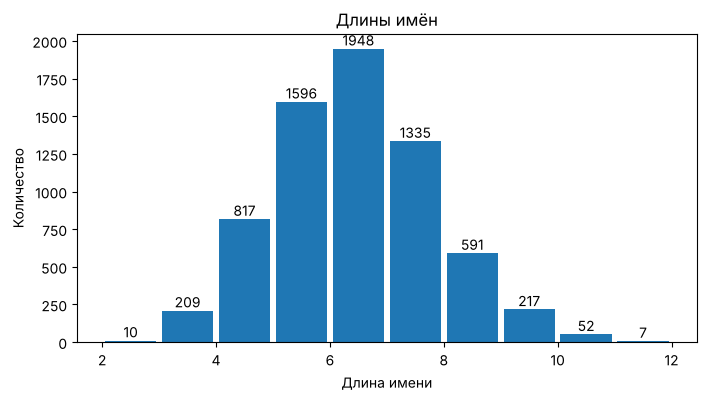

In [4]:
names['name_length'] = names.name.str.len()
ax = names.name_length.plot.hist(bins=range(2, 13), rwidth=0.9, figsize=(8, 4))
ax.bar_label(ax.containers[0])
plt.xlabel('Длина имени')
plt.ylabel('Количество')
plt.title('Длины имён')
plt.show()

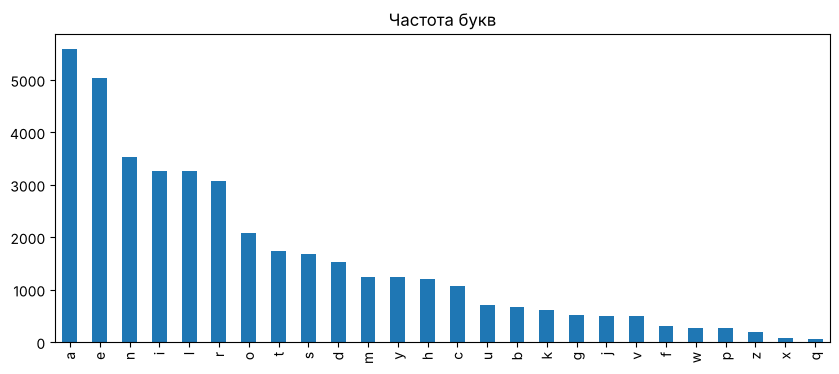

In [5]:
letters = pd.Series(list(names.name.str.lower().str.cat())).value_counts()
letters.plot.bar(figsize=(10, 4))
plt.title('Частота букв')
plt.show()

In [6]:
# последняя буква сильно связана с полом
last_letter = names.name.str[-1].str.lower()
pd.crosstab(last_letter, names.gender).sort_values('girl', ascending=False).head(8)

gender,boy,girl
name,,
a,117,1484
e,527,861
n,785,269
y,328,197
i,46,157
h,88,116
l,270,80
s,231,57


In [7]:
# при этом в разметке есть шум: каждое имя встречается один раз, и часть явно женских имён отмечена как boy
names[names.name.isin(['Mary', 'Anna', 'Emma', 'Elizabeth', 'Maria', 'Helen'])]

,name,gender,name_length
331,Mary,boy,4
528,Anna,boy,4
612,Emma,boy,4
648,Elizabeth,boy,9
1053,Helen,boy,5
2200,Maria,boy,5


**Вывод:** классы сбалансированы (3437 мальчиков и 3345 девочек). Большинство имён длиной 5-7 букв, самое длинное 11. Окончание сильно связано с полом: из 1601 имени на -a 1484 женские. Каждое имя встречается в датасете один раз, и часть явно женских имён (Mary, Anna, Emma) помечена как boy, видимо при сборке данных оставили только первое вхождение имени. Это шум в разметке, из-за него AUC около 1 получить нельзя.

## 3. Подготовка

Имена приводим к нижнему регистру, добавляем `^` в начало, `$` в конец и дополняем пробелами до максимальной длины (11 букв + 2 символа = 13). Пробел получает id 0: в лоссе по буквам его не учитываем (`ignore_index=0`), иначе модель получает бонус за то, что после конца имени угадывает пробелы.

In [8]:
names['name'] = names.name.str.lower()
y = (names.gender == 'boy').astype(int).values   # 1 - мальчик, 0 - девочка

int_to_token, token_to_int = make_vocab(names.name)
n_tokens = len(int_to_token)
max_len = names.name_length.max() + 2

X = encode_names(names.name, token_to_int, max_len)
print(n_tokens, max_len)
print(names.name[0], X[0])

29 13
john [ 1 12 17 10 16  2  0  0  0  0  0  0  0]


In [9]:
# 80 / 10 / 10, делим индексы, чтобы потом использовать то же разбиение и для бустинга
idx = np.arange(len(names))
train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=21, stratify=y)
valid_idx, test_idx = train_test_split(test_idx, test_size=0.5, random_state=42, stratify=y[test_idx])
print(len(train_idx), len(valid_idx), len(test_idx))

5425 678 679


In [10]:
def make_loaders(X):
    g = torch.Generator()
    g.manual_seed(42)
    train_dl = DataLoader(customDataset(X[train_idx], y[train_idx]), batch_size=32, shuffle=True, generator=g)
    valid_dl = DataLoader(customDataset(X[valid_idx], y[valid_idx]), batch_size=128)
    test_dl = DataLoader(customDataset(X[test_idx], y[test_idx]), batch_size=128)
    return train_dl, valid_dl, test_dl

train_dl, valid_dl, test_dl = make_loaders(X)

In [11]:
def plot_losses(train_losses, valid_losses, title):
    epochs = range(1, len(train_losses) + 1)
    plt.figure(figsize=(8, 4))
    plt.plot(epochs, train_losses, label='train', c='r')
    plt.plot(epochs, valid_losses, label='valid', c='royalblue')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(title)
    plt.grid()
    plt.legend()
    plt.show()

def sample_names(model, n=10, start='', temperature=0.7):
    return [generate_name(model, int_to_token, token_to_int, start, temperature, max_len, device) for _ in range(n)]

## 4. Генерация имён: RNN, GRU, LSTM

Модель (`custom_RNN`): эмбеддинг буквы -> рекуррентная ячейка -> линейный слой в логиты следующей буквы. Вторая голова (два линейных слоя) по последнему состоянию предсказывает пол. Здесь учим только на следующую букву, голова пола не обучается.

Генерация: начинаем с `^` (или с заданного начала имени), берём softmax(logits / temperature) и случайно выбираем следующую букву, пока не встретим `$`. Маленькая температура -> почти всегда самая вероятная буква, большая -> хаос.

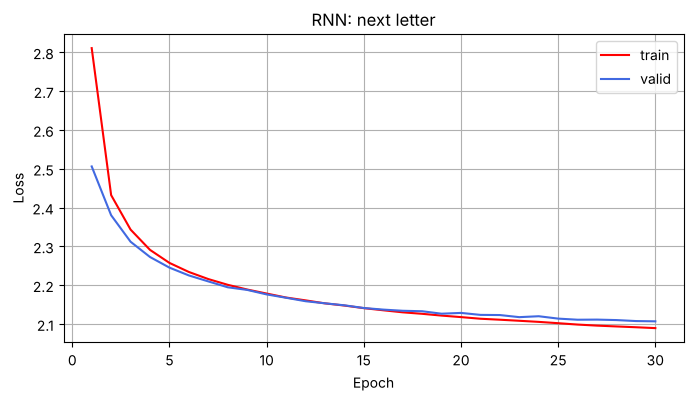

RNN ['marline', 'cara', 'datan', 'jawilan', 'jussa', 'gerris', 'bemar', 'arlon', 'estine', 'loe']


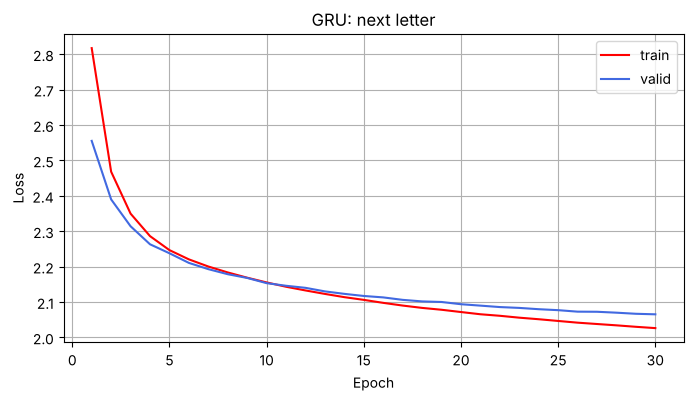

GRU ['danio', 'havin', 'ardit', 'colett', 'marley', 'jeann', 'gelie', 'laine', 'renna', 'dim']


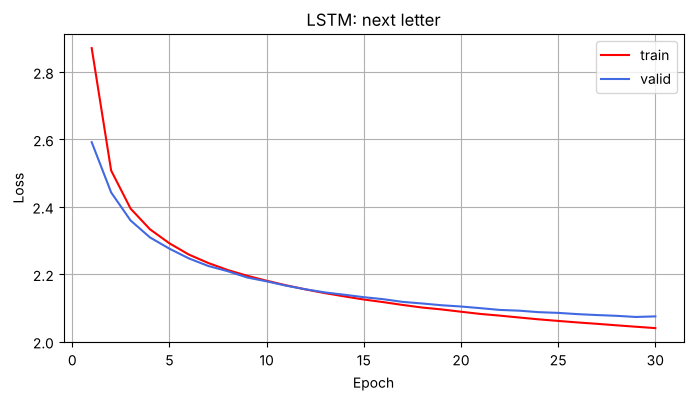

LSTM ['craylen', 'trister', 'deniet', 'evell', 'cherda', 'hirlenne', 'aliusta', 'krackia', 'marley', 'griston']


In [12]:
blocks = {'RNN': custom_VanillaRNN, 'GRU': custom_GRU_RNN, 'LSTM': custom_LSTM_RNN}
loss_token = nn.CrossEntropyLoss(ignore_index=PAD_ID)

token_models = {}
token_results = {}
for name, block in blocks.items():
    set_seed(42)
    model = custom_RNN(size_letter=16, size_hidden=32, rnn_block=block, n_tokens=n_tokens)
    train_losses, valid_losses = fit(model, train_dl, valid_dl, loss_token, device, pred='next_token', epochs=30)
    plot_losses(train_losses, valid_losses, f'{name}: next letter')
    token_models[name] = model
    token_results[name] = {
        'valid loss': valid_losses[-1],
        'PPL valid': perplexity_from_probs(valid_dl, model, device),
        'ROC AUC test (пол не учили)': evaluate_class(test_dl, model, device),
    }
    print(name, sample_names(model))

In [13]:
pd.DataFrame(token_results).T

,valid loss,PPL valid,ROC AUC test (пол не учили)
RNN,2.107067,8.245216,0.470587
GRU,2.065469,7.937459,0.495618
LSTM,2.074938,8.015361,0.366149


In [14]:
model = token_models['GRU']
for t in [0.3, 0.7, 1.0, 1.5]:
    print(f't={t}:', sample_names(model, 8, temperature=t))
print()
for start in ['mar', 'al', 'jo']:
    print(start, sample_names(model, 8, start=start))

t=0.3: ['alexa', 'mardin', 'charlen', 'earlen', 'marila', 'ellie', 'lanie', 'lucie']
t=0.7: ['rando', 'keline', 'tobetna', 'zelia', 'tamikia', 'nargery', 'javer', 'allah']
t=1.0: ['nava', 'flanda', 'nelt', 'jasela', 'dolha', 'manderna', 'dodvi', 'eriphie']
t=1.5: ['chepza', 'ereston', 'jeliciat', 'ouw', 'imala', 'decey', 'cloperwene', 'olierr']

mar ['mardus', 'marsine', 'marde', 'marice', 'mardettie', 'marette', 'mariane', 'marina']
al ['alevia', 'aletto', 'alvello', 'alissan', 'alinta', 'albert', 'aladdin', 'alberrid']
jo ['jorand', 'jote', 'jonie', 'jonett', 'josa', 'jomat', 'jonda', 'joselia']


**Вывод:** все три модели придумывают правдоподобные имена (marley, renna, alexa, marina), иногда попадаются странные вроде tobetna. При температуре 0.3 имена простые и похожи друг на друга, при 1.5 начинается мусор (ouw, olierr). Если задать начало, модель его продолжает: из mar получаются marina, mariane, marette. По перплексии GRU чуть лучше (7.9 против 8.2 у RNN), но разница маленькая: имена короткие, и долгая память для генерации не нужна.

ROC AUC по полу около 0.5 (у LSTM даже 0.37): голову пола здесь не учили, её выход это просто случайные числа, и они могут оказаться как выше, так и ниже 0.5.

## 5. Как сравнивать генераторы: перплексия

Своя идея метрики: сгенерировать много имён и посчитать, какая доля из них есть в реальном словаре имён, плюс сколько из них уникальных (чтобы модель не выдавала одно и то же). Минус: нужен большой словарь, а новое правдоподобное имя считается ошибкой.

Стандартная метрика для языковых моделей это **перплексия**. Модель даёт вероятность каждой правильной следующей буквы, перплексия это обратная средняя геометрическая этих вероятностей:

$$PPL = \left(\prod_{t=1}^{N} p(x_t \mid x_{<t})\right)^{-1/N} = \exp\left(-\frac{1}{N}\sum_{t=1}^{N}\log p(x_t \mid x_{<t})\right)$$

Внутри экспоненты стоит ровно cross entropy, которую мы и минимизируем, поэтому $PPL = e^{CE}$. Смысл: PPL = k значит, что модель в среднем "выбирает" как будто из k равновероятных букв. Идеальная модель даёт 1.

Случайная модель, у которой все 29 токенов равновероятны: $PPL = \left((1/29)^N\right)^{-1/N} = 29$.

In [15]:
random_ppl = np.exp(-np.log(1 / n_tokens))

freq_model = FreqModel(n_tokens)
freq_model.train(train_dl.dataset.X_next)

ppl = {'random': random_ppl, 'частоты букв': perplexity_frequency(freq_model, valid_dl)}
for name, model in token_models.items():
    ppl[name + ' (по вероятностям)'] = perplexity_from_probs(valid_dl, model, device)
    ppl[name + ' (exp(loss))'] = perplexity_from_loss(token_results[name]['valid loss'])
pd.Series(ppl, name='PPL valid').round(2)

random                    29.00
частоты букв              17.03
RNN (по вероятностям)      8.25
RNN (exp(loss))            8.22
GRU (по вероятностям)      7.94
GRU (exp(loss))            7.89
LSTM (по вероятностям)     8.02
LSTM (exp(loss))           7.96
Name: PPL valid, dtype: float64

**Вывод:** случайная модель даёт 29, модель частот букв 17, рекуррентные сети около 8. То есть сеть в среднем выбирает как будто из 8 букв, а не из 29: она реально выучила, какие буквы идут друг за другом. Две версии перплексии почти совпадают, небольшая разница из-за того, что exp(loss) усредняет по батчам, а не по буквам.

## 6. Классификация пола

Теперь учим только голову пола. Два варианта лосса:

- **BCE**: один выход (логит), sigmoid даёт вероятность мальчика;
- **NLL**: два выхода, log_softmax, потом NLLLoss.

Для двух классов это одно и то же: softmax от двух логитов равен sigmoid от их разности, а NLL от log_softmax это обычная cross entropy. Разница только в лишнем параметре у второго варианта.

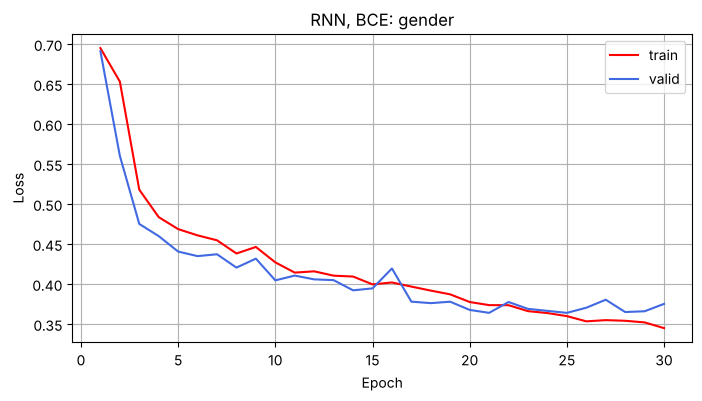

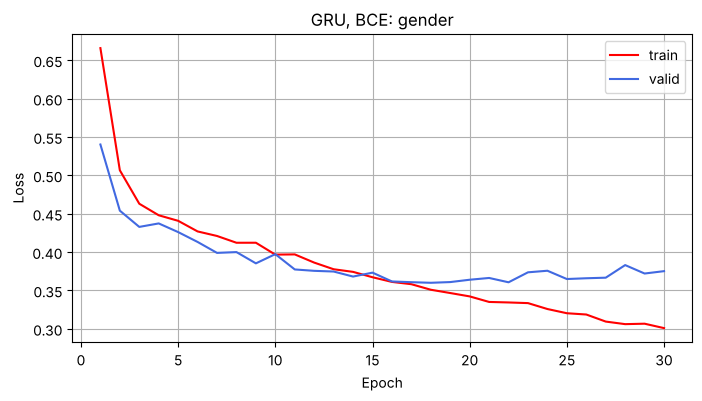

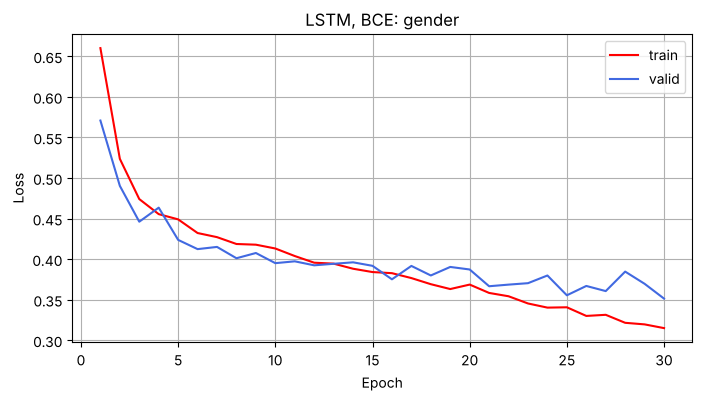

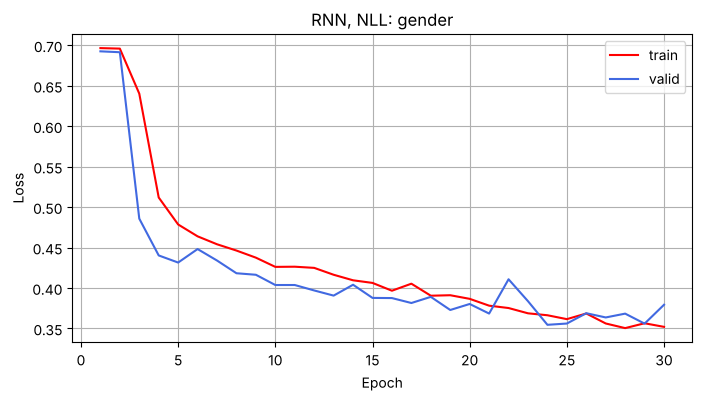

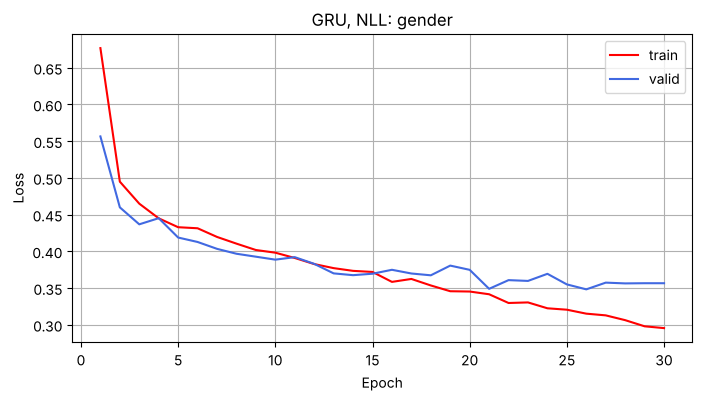

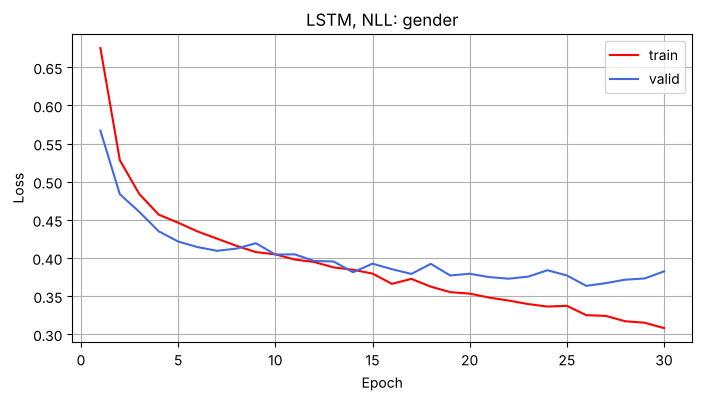

,BCE,NLL
GRU,0.894,0.900
LSTM,0.894,0.885
RNN,0.875,0.880


In [16]:
gender_results = {}
for loss_name, loss_fn, n_outputs in [('BCE', nn.BCEWithLogitsLoss(), 1), ('NLL', nn.NLLLoss(), 2)]:
    for name, block in blocks.items():
        set_seed(42)
        model = custom_RNN(size_letter=16, size_hidden=32, rnn_block=block, n_tokens=n_tokens, n_outputs=n_outputs)
        train_losses, valid_losses = fit(model, train_dl, valid_dl, loss_fn, device, pred='gender', epochs=30, loss_name=loss_name)
        plot_losses(train_losses, valid_losses, f'{name}, {loss_name}: gender')
        gender_results[(name, loss_name)] = evaluate_class(test_dl, model, device, loss_name)

pd.Series(gender_results, name='ROC AUC test').unstack().round(3)

In [17]:
# голова букв в этих моделях не обучалась, поэтому имена получаются случайными
sample_names(model)

['fcvnnbcweigi',
 'agsnclqaailm',
 'qvcibvk^gmrm',
 'ytr^ndoco',
 '',
 '',
 'nzjuyhijyokh',
 '^bcncih',
 'mreifcota',
 'qu']

**Вывод:** BCE и NLL дают почти одинаковый AUC (разница меньше 0.01 и в разные стороны), как и должно быть, для двух классов это одна и та же функция потерь. Я бы выбрал BCE: один выход вместо двух, проще. Из ячеек лучше всех GRU (около 0.9), обычная RNN чуть хуже (0.88).

## 7. Затухание градиентов

Имена короткие (в среднем 6 букв), а пол предсказываем по последнему состоянию, после пробелов. Для 13 шагов затухание почти не мешает, поэтому проверим на более длинных последовательностях: просто добавим больше пробелов в конце. Буквы имени останутся в начале, а предсказание будет в самом конце, через 20-40 "пустых" шагов. Сеть должна пронести информацию об имени через все эти шаги.

In [18]:
pad_results = {}
for length in [13, 30, 50]:
    train_long, valid_long, test_long = make_loaders(encode_names(names.name, token_to_int, length))
    for name, block in blocks.items():
        set_seed(42)
        model = custom_RNN(size_letter=16, size_hidden=32, rnn_block=block, n_tokens=n_tokens)
        fit(model, train_long, valid_long, nn.BCEWithLogitsLoss(), device, pred='gender', epochs=15)
        pad_results[(name, length)] = evaluate_class(valid_long, model, device)

pd.Series(pad_results, name='ROC AUC valid').unstack().round(3)

,13,30,50
GRU,0.916,0.910,0.910
LSTM,0.904,0.667,0.518
RNN,0.899,0.509,0.500


Посмотрим, откуда это берётся. Во время обучения на длине 30 сохраняем градиент лосса по эмбеддингу на каждой позиции (через `register_full_backward_hook` на слое эмбеддингов) и берём его норму. Позиция 0 это `^`, буквы имени примерно на позициях 1-8, дальше пробелы.

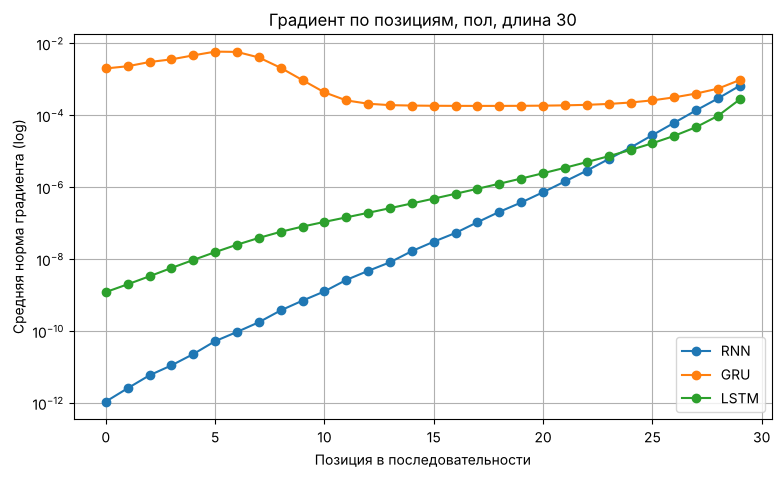

In [19]:
train_long, valid_long, test_long = make_loaders(encode_names(names.name, token_to_int, 30))

grad_results = {}
for name, block in blocks.items():
    set_seed(42)
    model = custom_RNN(size_letter=16, size_hidden=32, rnn_block=block, n_tokens=n_tokens)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    grads = grad_by_position(model, train_long, nn.BCEWithLogitsLoss(), optimizer, device, pred='gender', epochs=15)
    grad_results[name] = grads.mean(dim=0)   # среднее по эпохам

plt.figure(figsize=(9, 5))
for name, g in grad_results.items():
    plt.plot(g.numpy(), marker='o', label=name)
plt.yscale('log')
plt.xlabel('Позиция в последовательности')
plt.ylabel('Средняя норма градиента (log)')
plt.title('Градиент по позициям, пол, длина 30')
plt.grid()
plt.legend()
plt.savefig('images/gradient_by_position.png', bbox_inches='tight')
plt.show()

У LSTM есть известный приём: инициализировать смещение forget-гейта единицей. Тогда в начале обучения $f_t \approx 0.73$ вместо 0.5, и память забывается медленнее.

In [20]:
set_seed(42)
model = custom_RNN(size_letter=16, size_hidden=32, rnn_block=custom_LSTM_RNN, n_tokens=n_tokens)
nn.init.constant_(model.rnn_cell.W_f.bias, 1.0)
fit(model, train_long, valid_long, nn.BCEWithLogitsLoss(), device, pred='gender', epochs=15)
print('LSTM, forget bias = 1, длина 30:', evaluate_class(valid_long, model, device))

LSTM, forget bias = 1, длина 30: 0.8769582927168917


На длине 13 все три ячейки работают примерно одинаково. Когда после имени 17 и больше пробелов, обычная RNN падает до 0.5, то есть вообще перестаёт понимать пол. LSTM тоже ломается (0.67 на длине 30 и 0.52 на 50), а GRU держится на 0.91.

На графике видно, почему так. У RNN градиент от конца к началу уменьшается примерно в $10^8$ раз, до букв имени сигнал просто не доходит, и сеть не может научиться их помнить. У LSTM спад медленнее, но тоже экспоненциальный. GRU научилась копировать состояние через пробелы ($z_t \approx 0$), и градиент на буквах у неё даже больше, чем на пробелах. LSTM с forget bias = 1 сразу поднимается до 0.88: с самого начала она меньше забывает и успевает этому научиться.

**Вывод:** затухание градиентов реально мешает обычной RNN, когда между важной информацией и предсказанием много шагов. На коротких именах (13 шагов) этого почти не видно, поэтому для эксперимента последовательности пришлось удлинить. В задаче генерации такой проблемы почти нет: лосс считается на каждом шаге, и каждой букве достаточно помнить несколько предыдущих. GRU с этим справляется лучше всех, LSTM помогает правильная инициализация forget-гейта.

## 8. Multitask: генерация + пол

Одна GRU, общий лосс: `CE(буквы) + BCE(пол)`. Голова пола получает от задачи генерации дополнительный сигнал о том, как устроены имена.

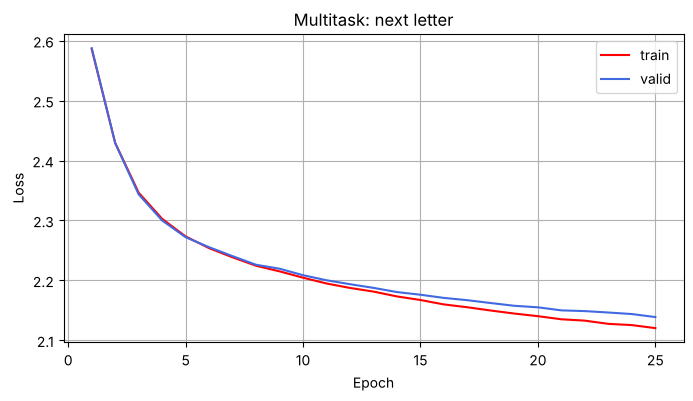

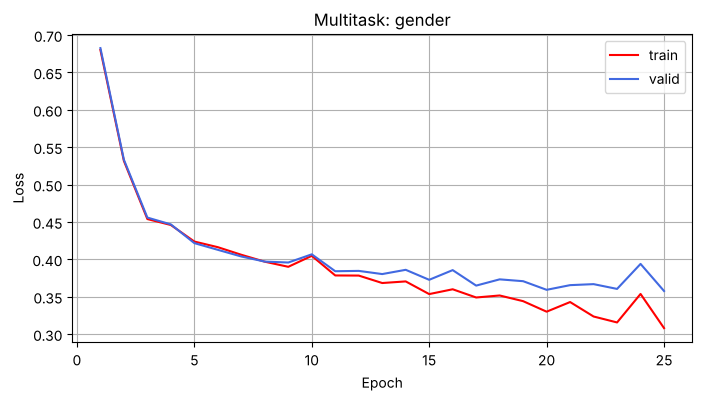

In [21]:
set_seed(42)
multi_model = custom_RNN(size_letter=16, size_hidden=32, rnn_block=custom_GRU_RNN, n_tokens=n_tokens)
history = fit_both(multi_model, train_dl, valid_dl, loss_token, nn.BCEWithLogitsLoss(), device, epochs=25)

plot_losses(history['train_token'], history['valid_token'], 'Multitask: next letter')
plot_losses(history['train_gender'], history['valid_gender'], 'Multitask: gender')

In [22]:
print('ROC AUC test:', evaluate_class(test_dl, multi_model, device))
print('PPL valid:', perplexity_from_probs(valid_dl, multi_model, device))
sample_names(multi_model)

ROC AUC test: 0.8869055883373828
PPL valid: 8.531898498535156


['kathalen',
 'loman',
 'ralyne',
 'amer',
 'idley',
 'jadyn',
 'minna',
 'ellenne',
 'calis',
 'charia']

**Вывод:** ROC AUC 0.887, чуть ниже, чем у GRU, обученной только на пол (0.894), и перплексия чуть хуже (8.5 против 7.9). Сеть маленькая (скрытое состояние 32), и двум задачам в ней тесно. Зато одна модель и придумывает нормальные имена (kathalen, jadyn, minna), и определяет пол.

## 9. Эмбеддинги букв

Берём матрицу эмбеддингов из multitask модели (29 векторов по 16 чисел) и сжимаем в 2D через t-SNE и PCA. Гласные отмечаем отдельным цветом.

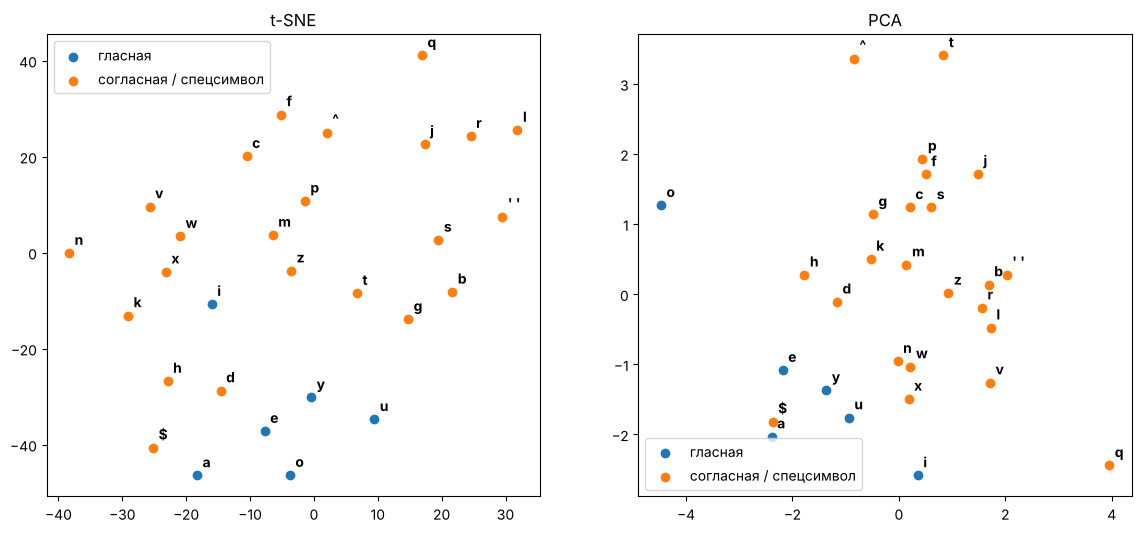

In [23]:
embeddings = multi_model.embedding.weight.detach().cpu().numpy()
vowels = set('aeiouy')
is_vowel = np.array([int_to_token[i] in vowels for i in range(n_tokens)])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (title, emb2d) in zip(axes, [
    ('t-SNE', TSNE(n_components=2, perplexity=6, random_state=42).fit_transform(embeddings)),
    ('PCA', PCA(n_components=2).fit_transform(embeddings)),
]):
    ax.scatter(emb2d[is_vowel, 0], emb2d[is_vowel, 1], label='гласная')
    ax.scatter(emb2d[~is_vowel, 0], emb2d[~is_vowel, 1], label='согласная / спецсимвол')
    for i in range(n_tokens):
        ax.annotate(repr(int_to_token[i]) if int_to_token[i] == ' ' else int_to_token[i],
                    emb2d[i], xytext=(4, 6), textcoords='offset points', fontweight='bold')
    ax.set_title(title)
    ax.legend()
plt.savefig('images/letter_embeddings.png', bbox_inches='tight')
plt.show()

**Вывод:** на t-SNE гласные a, e, o, u, y собрались внизу в одну группу, i чуть в стороне. Рядом с ними оказался `$` (конец имени): после гласной имя часто заканчивается. На PCA `a` и конец имени вообще почти в одной точке, видимо из-за того, что окончание на -a это главный признак пола. Гласные на PCA тоже вместе в нижней левой части (кроме o). Редкая q лежит далеко от всех. То есть модель сама, без подсказок, поняла, что гласные ведут себя похоже.

## 10. Бонус

### 10.1 Подбор гиперпараметров GRU (optuna)

Подбирали на valid размеры эмбеддинга и скрытого слоя, learning rate, dropout и число эпох для GRU, которая учится только на пол. Подбор долгий, поэтому код закомментирован, ниже лучшие параметры.

In [24]:
# import optuna
#
# def objective(trial):
#     params = {
#         'size_letter': trial.suggest_int('size_letter', 8, 128),
#         'size_hidden': trial.suggest_int('size_hidden', 8, 256),
#         'p': trial.suggest_float('p', 0, 1),
#         'p1': trial.suggest_float('p1', 0, 1),
#     }
#     lr = trial.suggest_float('lr', 1e-4, 3e-3, log=True)
#     epochs = trial.suggest_int('epochs', 5, 50)
#     set_seed(42)
#     model = custom_RNN(rnn_block=custom_GRU_RNN, n_tokens=n_tokens, **params).to(device)
#     optimizer = torch.optim.Adam(model.parameters(), lr=lr)
#     for epoch in range(epochs):
#         train_loop(train_dl, model, nn.BCEWithLogitsLoss(), optimizer, device, pred='gender')
#         auc = evaluate_class(valid_dl, model, device)
#         trial.report(auc, epoch)
#         if trial.should_prune():
#             raise optuna.TrialPruned()
#     return auc
#
# study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42),
#                             pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5))
# study.optimize(objective, n_trials=40)
# study.best_params

best_params = {'size_letter': 118, 'size_hidden': 255, 'lr': 0.00037, 'p': 0.55, 'p1': 0.65, 'epochs': 15}

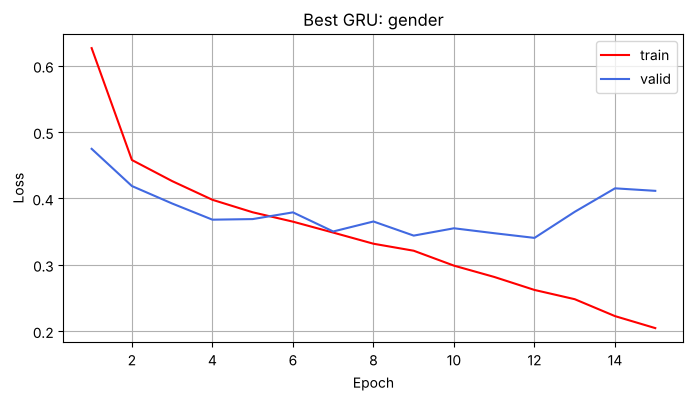

train 0.981
valid 0.9157
test 0.9065


In [25]:
set_seed(42)
best_model = custom_RNN(size_letter=best_params['size_letter'], size_hidden=best_params['size_hidden'],
                        rnn_block=custom_GRU_RNN, n_tokens=n_tokens, p=best_params['p'], p1=best_params['p1'])
train_losses, valid_losses = fit(best_model, train_dl, valid_dl, nn.BCEWithLogitsLoss(), device, pred='gender',
                                 epochs=best_params['epochs'], lr=best_params['lr'])
plot_losses(train_losses, valid_losses, 'Best GRU: gender')

for part, dl in [('train', train_dl), ('valid', valid_dl), ('test', test_dl)]:
    print(part, round(evaluate_class(dl, best_model, device), 4))

### 10.2 Эмбеддинги имён

Эмбеддинг имени это последнее скрытое состояние сети (то, по чему голова предсказывает пол). Сжимаем эмбеддинги имён из теста через t-SNE.

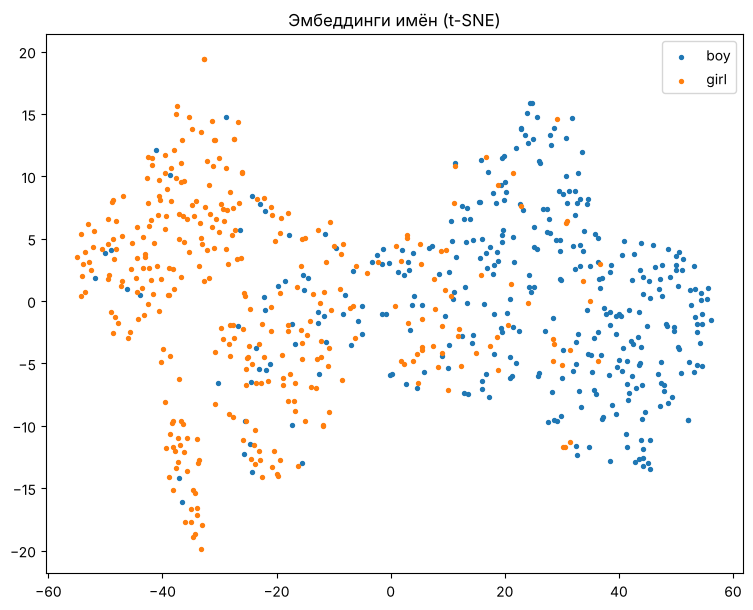

In [26]:
best_model.eval()
with torch.no_grad():
    name_emb = torch.cat([best_model.get_name_embedding(X_b.to(device)).cpu() for X_b, _, _ in test_dl]).numpy()

emb2d = TSNE(n_components=2, random_state=42).fit_transform(name_emb)
y_test = y[test_idx]
plt.figure(figsize=(9, 7))
plt.scatter(emb2d[y_test == 1, 0], emb2d[y_test == 1, 1], s=8, label='boy')
plt.scatter(emb2d[y_test == 0, 0], emb2d[y_test == 0, 1], s=8, label='girl')
plt.title('Эмбеддинги имён (t-SNE)')
plt.legend()
plt.show()

**Вывод:** девочки собрались слева, мальчики справа, в середине они перемешаны. Отдельная плотная группа девочек внизу слева похожа на имена на -a. Подобранная GRU даёт 0.907 на тесте, это почти не лучше простой GRU (0.894), зато сильно переобучается (0.98 на train).

### 10.3 Готовые слои из torch

Та же архитектура на `nn.RNN`, `nn.GRU`, `nn.LSTM`, те же размеры и эпохи. Сравниваем качество и время с ручными ячейками. Отдельно пробуем двунаправленную GRU в 2 слоя: она читает имя с обеих сторон, поэтому сразу видит окончание. Её учим только на пол: в задаче генерации обратный проход уже видел следующую букву, то есть подглядывал бы в ответ.

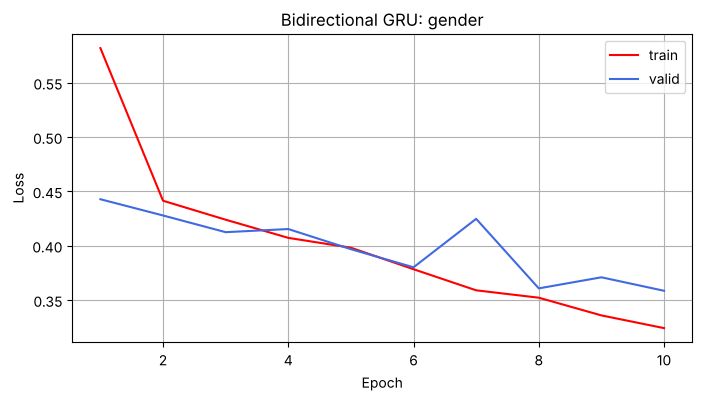

ROC AUC test  время, с
RNN      свои          0.877    16.269
         torch         0.886    14.459
GRU      свои          0.897    27.110
         torch         0.887    25.276
LSTM     свои          0.892    29.243
         torch         0.889    16.093
BiGRU x2 torch         0.907       NaN

In [27]:
import time

torch_results = {}
for cell in ['rnn', 'gru', 'lstm']:
    for kind in ['свои', 'torch']:
        set_seed(42)
        if kind == 'свои':
            model = custom_RNN(size_letter=16, size_hidden=32, rnn_block=blocks[cell.upper()], n_tokens=n_tokens)
        else:
            model = TorchRNN(size_letter=16, size_hidden=32, cell=cell, n_tokens=n_tokens)
        start = time.time()
        fit(model, train_dl, valid_dl, nn.BCEWithLogitsLoss(), device, pred='gender', epochs=30)
        torch_results[(cell.upper(), kind)] = {'ROC AUC test': evaluate_class(test_dl, model, device),
                                               'время, с': time.time() - start}

set_seed(42)
bi_model = TorchRNN(size_letter=64, size_hidden=40, cell='gru', n_tokens=n_tokens, bidirectional=True, num_layers=2)
train_losses, valid_losses = fit(bi_model, train_dl, valid_dl, nn.BCEWithLogitsLoss(), device, pred='gender', epochs=10)
plot_losses(train_losses, valid_losses, 'Bidirectional GRU: gender')
torch_results[('BiGRU x2', 'torch')] = {'ROC AUC test': evaluate_class(test_dl, bi_model, device), 'время, с': None}

pd.DataFrame(torch_results).T.round(3)

**Вывод:** по качеству свои ячейки и готовые слои одинаковые (0.88-0.90), разница в пределах случайности. Значит, ячейки написаны правильно. По скорости готовая LSTM почти в 2 раза быстрее моей на CPU, на GPU разница будет ещё больше, потому что torch использует cuDNN. Двунаправленная GRU в 2 слоя дала 0.907: она сразу видит окончание имени.

### 10.4 Градиентный бустинг

Признаки: длина имени, число гласных и количество буквенных n-грамм длины 1-3. К имени добавляем символы начала и конца (`^` и `$`), чтобы n-граммы знали, где имя начинается и где заканчивается. Так появляются признаки вида "имя заканчивается на a". Словарь n-грамм строим только по train. Разбиение то же, что и для сетей.

In [28]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.ensemble import GradientBoostingClassifier

marked = ('^' + names.name + '$').values
vectorizer = CountVectorizer(analyzer='char', ngram_range=(1, 3), min_df=3, lowercase=False)
vectorizer.fit(marked[train_idx])

ngrams = pd.DataFrame(vectorizer.transform(marked).toarray(), columns=vectorizer.get_feature_names_out())
features = pd.concat([
    pd.DataFrame({'name_len': names.name.str.len(),
                  'vowels_count': names.name.apply(lambda x: sum(ch in 'aeiouy' for ch in x))}),
    ngrams
], axis=1)
features.shape

(6782, 2299)

In [29]:
# параметры подобраны optuna на valid
gb = GradientBoostingClassifier(n_estimators=414, max_depth=8, min_samples_split=7, max_features='log2',
                                subsample=0.99, random_state=42)
gb.fit(features.iloc[train_idx], y[train_idx])

for part, part_idx in [('train', train_idx), ('valid', valid_idx), ('test', test_idx)]:
    print(part, round(roc_auc_score(y[part_idx], gb.predict_proba(features.iloc[part_idx])[:, 1]), 4))

train 0.9825
valid 0.9268
test 0.923


In [30]:
pd.Series(gb.feature_importances_, index=features.columns).sort_values(ascending=False).head(15)

a$              0.181458
n$              0.022971
vowels_count    0.016226
i               0.016111
o               0.012574
e$              0.012228
i$              0.010916
name_len        0.010689
na$             0.010265
na              0.010036
l$              0.009869
la$             0.008432
ia$             0.008370
o$              0.007992
on              0.007905
dtype: float64

**Вывод:** бустинг на n-граммах дал 0.923 на тесте, это лучше всех сетей. Самый важный признак `a$`, то есть имя заканчивается на a, дальше окончания на n, e и i. Получается, для пола по имени достаточно окончания, и простые признаки с ним справляются не хуже RNN. Сеть выигрывает в другом: она одна умеет ещё и генерировать имена.

## 11. Сохранение модели

Сохраняем multitask модель в pickle, загружаем заново и делаем предсказания для теста (`models/test_predictions.csv`).

In [31]:
import pickle

with open('models/multitask_gru.pkl', 'wb') as f:
    pickle.dump({'state_dict': multi_model.state_dict(),
                 'arch': {'size_letter': 16, 'size_hidden': 32, 'n_tokens': n_tokens}}, f)

with open('models/multitask_gru.pkl', 'rb') as f:
    saved = pickle.load(f)
loaded = custom_RNN(rnn_block=custom_GRU_RNN, **saved['arch'])
loaded.load_state_dict(saved['state_dict'])
loaded = loaded.to(device)

probs, labels = predict_gender(test_dl, loaded, device)
pd.DataFrame({'name': names.name.values[test_idx], 'gender': labels, 'prob_boy': probs}).to_csv('models/test_predictions.csv', index=False)
print('ROC AUC test:', roc_auc_score(labels, probs))

ROC AUC test: 0.8869055883373828
